# Aplicación de RNN y LSTM a series de tiempo

En esta aplicación se utiliza una **LSTM** para pronosticar la concentración de
partículas **PM2.5** a partir de observaciones anteriores. El ejemplo procede del
archivo `ann_model.ipynb` y conserva sus **celdas de código originales**.

La LSTM es una arquitectura recurrente. El archivo de origen presenta aquí un
modelo de **LSTM apiladas**; no incluye en esta aplicación un modelo independiente
con `SimpleRNN`. La teoría general de RNN y LSTM se encuentra en el capítulo
correspondiente del libro.

```{figure} ./imgs/flujo_series_temporales.png
:name: flujo-series-temporales
:align: center
:alt: Flujo desde observaciones PM2.5 hasta predicción con LSTM y evaluación.

Flujo del ejemplo extraído: lectura, partición temporal, escalado, construcción de
ventanas, LSTM, predicción y evaluación.
```

### Definiciones de series de tiempo

Una **serie de tiempo** es una colección de observaciones ordenadas según el instante
en que se registran. Puede representarse como:

$$
y_1,y_2,\dots,y_T,
$$

donde $y_t$ es el valor observado en el instante $t$. En el ejemplo, la variable
seleccionada es la concentración de PM2.5.

- **Frecuencia:** intervalo previsto entre registros, como una hora o un día. Es
  importante verificar si existen observaciones faltantes o irregulares.
- **Tendencia:** evolución general de la serie a lo largo del tiempo.
- **Estacionalidad:** patrón que se repite aproximadamente con cierta frecuencia,
  como un comportamiento diario o anual.
- **Rezago** (*lag*): valor observado en un instante anterior al de referencia.
- **Ventana temporal:** conjunto de observaciones pasadas utilizado como entrada.
- **Horizonte de predicción:** distancia temporal o número de pasos entre la última
  información disponible y el valor que se busca pronosticar.
- **Residuo o error de predicción:** diferencia entre el valor observado y el
  pronosticado, por ejemplo $e_t=y_t-\hat y_t$.

### Formulación del ejemplo

La función `makeXy` utiliza **siete observaciones anteriores** para predecir la
siguiente. De forma esquemática:

$$
\underbrace{(y_{t-6},\dots,y_t)}_{\text{ventana de entrada}}
\longrightarrow
\underbrace{y_{t+1}}_{\text{objetivo}}.
$$

Tras el escalado, el arreglo de entrada de la LSTM tiene la forma
$(\text{muestras},7,1)$: **siete pasos** y una característica por paso.

```{important}
El conjunto de datos tiene registros horarios, pero el código elimina filas con
PM2.5 faltante. Por ello, siete observaciones consecutivas del arreglo **no están
garantizadas como siete horas consecutivas** si existen huecos en las fechas. No
se trata de una ventana de siete días.
```

### Datos y alcance

El ejemplo usa el conjunto de contaminación atmosférica de Pekín, disponible en el
[repositorio UCI](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data). La
celda original lo lee desde una copia en GitHub; su dirección se conserva sin cambios.
La descarga requiere conexión a internet.

El código divide los registros cronológicamente: antes de 2014 se emplean para
**entrenamiento** y los posteriores para **validación**. No se define un tercer
conjunto de prueba independiente.

```{note}
Se conservan las salidas originales que estaban guardadas en el notebook. No se han
recalculado en esta extracción y pueden depender de archivos y modelos previos.
```


Se conserva la aplicación LSTM del archivo de origen y se presentan las tareas del proyecto de series de tiempo orientadas a **RNN o LSTM**.


## Aplicación: LSTM para la predicción de series de tiempo

- Continuaremos usando el conjunto de datos sobre contaminación del aire (`pm2.5`) usando LSTM. La lectura y el ***preprocesamiento de los datos se presentan en las celdas siguientes***. El conjunto de datos original se divide en dos conjuntos: *entrenamiento y validación*, que se usan para el entrenamiento y validación del modelo respectivamente.

- La función `makeXy` se utiliza para generar arreglos de regresores y objetivos: `X_train, X_val, y_train` y `y_val`. `X_train y X_val`, generados por la función `makeXy`, son ***arreglos 2D de forma (número de muestras, número de pasos de tiempo)***. Sin embargo, la ***entrada a las capas RNN debe ser de forma (número de muestras, número de pasos de tiempo, número de características por paso de tiempo)***.

- En este caso, estamos tratando solo con `pm2.5`, por lo tanto, el ***número de características por paso de tiempo es uno***. El número de pasos de tiempo es siete y el número de muestras es el mismo que el número de muestras en `X_train` y `X_val`, que se transforman a arreglos 3D

In [1]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import warnings
warnings.filterwarnings('ignore')

In [2]:
plot_fontsize = 18;

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/lihkir/Data/refs/heads/main/PRSA_data_2010.1.1-2014.12.31.csv', usecols=lambda column: column not in ['DEWP', 'TEMP', 'cbwd', 'Iws',	'Is', 'Ir'])

In [4]:
print('Shape of the dataframe:', df.shape)

Shape of the dataframe: (43824, 7)


In [5]:
df.head()

,No,year,month,day,hour,pm2.5,PRES
0,1,2010,1,1,0,NaN,1021.0
1,2,2010,1,1,1,NaN,1020.0
2,3,2010,1,1,2,NaN,1019.0
3,4,2010,1,1,3,NaN,1019.0
4,5,2010,1,1,4,NaN,1018.0


In [6]:
df.dropna(subset=['pm2.5'], axis=0, inplace=True)
df.reset_index(drop=True, inplace=True)

In [7]:
df['datetime'] = df[['year', 'month', 'day', 'hour']].apply(lambda row: datetime.datetime(year=row['year'], month=row['month'], day=row['day'],
                                                                                          hour=row['hour']), axis=1)
df.sort_values('datetime', ascending=True, inplace=True)

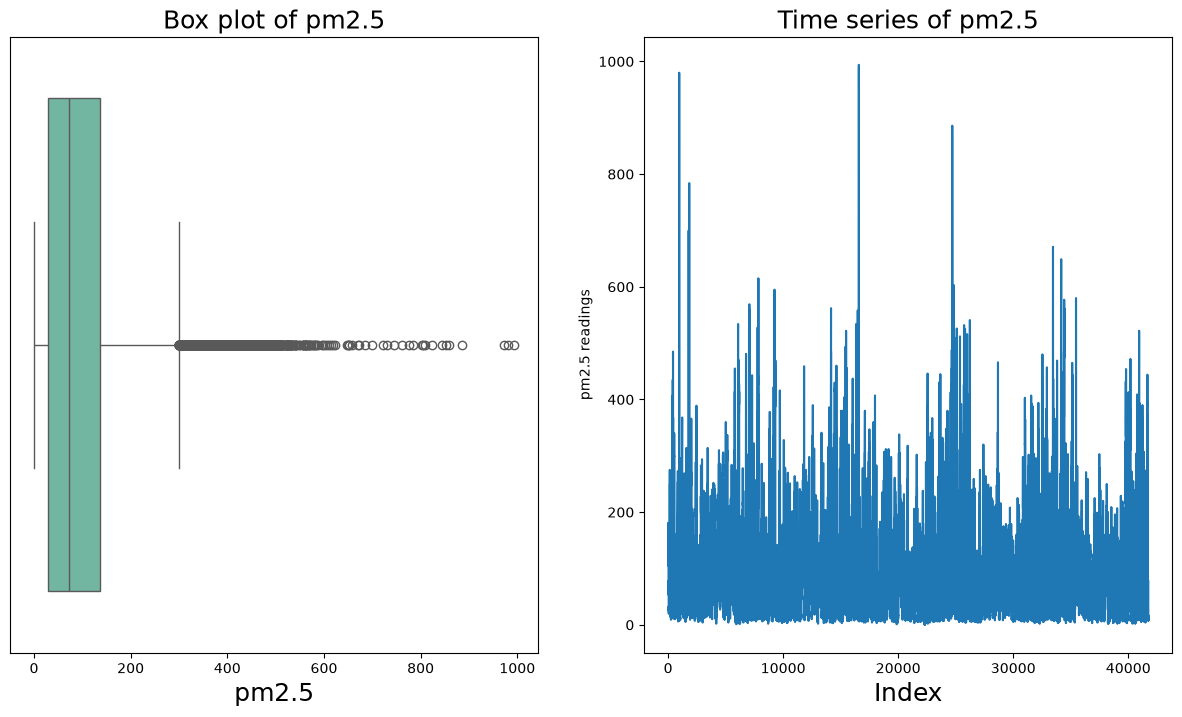

In [8]:
plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1) 
g1 = sns.boxplot(df['pm2.5'], orient="h", palette="Set2")
g1.set_title('Box plot of pm2.5', fontsize=plot_fontsize);
g1.set_xlabel(xlabel='pm2.5', fontsize=plot_fontsize)
g1.set(yticklabels=[])
g1.tick_params(left=False);

plt.subplot(1, 2, 2)
g2 = sns.lineplot(df['pm2.5'])
g2.set_title('Time series of pm2.5', fontsize=plot_fontsize)
g2.set_xlabel('Index', fontsize=plot_fontsize)
g2.set_ylabel('pm2.5 readings');

plt.show()

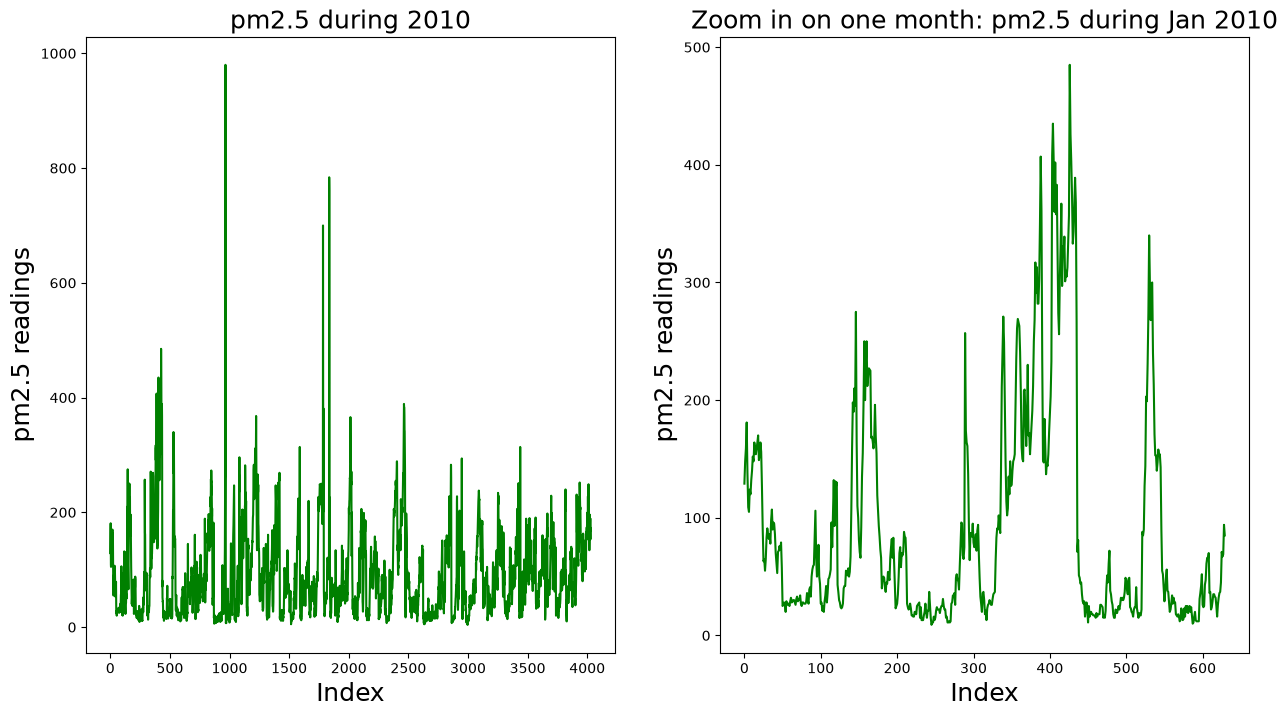

In [9]:
plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
g1 = sns.lineplot(df['pm2.5'].loc[df['datetime']<=datetime.datetime(year=2010,month=6,day=30)], color='g')
g1.set_title('pm2.5 during 2010', fontsize=plot_fontsize)
g1.set_xlabel('Index', fontsize=plot_fontsize)
g1.set_ylabel('pm2.5 readings', fontsize=plot_fontsize);

plt.subplot(1, 2, 2)
g = sns.lineplot(df['pm2.5'].loc[df['datetime']<=datetime.datetime(year=2010,month=1,day=31)], color='g')
g.set_title('Zoom in on one month: pm2.5 during Jan 2010', fontsize=plot_fontsize)
g.set_xlabel('Index', fontsize=plot_fontsize)
g.set_ylabel('pm2.5 readings', fontsize=plot_fontsize);

plt.show()

In [10]:
split_date = datetime.datetime(year=2014, month=1, day=1, hour=0)
df_train = df.loc[df['datetime']<split_date]
df_val = df.loc[df['datetime']>=split_date]
print('Shape of train:', df_train.shape)
print('Shape of test:', df_val.shape)

Shape of train: (33096, 8)
Shape of test: (8661, 8)


In [11]:
df_train.head()

,No,year,month,day,hour,pm2.5,PRES,datetime
0,25,2010,1,2,0,129.0,1020.0,2010-01-02 00:00:00
1,26,2010,1,2,1,148.0,1020.0,2010-01-02 01:00:00
2,27,2010,1,2,2,159.0,1021.0,2010-01-02 02:00:00
3,28,2010,1,2,3,181.0,1022.0,2010-01-02 03:00:00
4,29,2010,1,2,4,138.0,1022.0,2010-01-02 04:00:00


In [12]:
df_val.head()

,No,year,month,day,hour,pm2.5,PRES,datetime
33096,35065,2014,1,1,0,24.0,1014.0,2014-01-01 00:00:00
33097,35066,2014,1,1,1,53.0,1013.0,2014-01-01 01:00:00
33098,35067,2014,1,1,2,65.0,1013.0,2014-01-01 02:00:00
33099,35068,2014,1,1,3,70.0,1013.0,2014-01-01 03:00:00
33100,35069,2014,1,1,4,79.0,1012.0,2014-01-01 04:00:00


In [13]:
df_val.reset_index(drop=True, inplace=True)

In [14]:
scaler_pm25 = MinMaxScaler(feature_range=(0, 1))
df_train['scaled_pm2.5'] = scaler_pm25.fit_transform(df_train[['pm2.5']])
df_val['scaled_pm2.5'] = scaler_pm25.transform(df_val[['pm2.5']])

print('Shape of train:', df_train.shape)
print('Shape of val:', df_val.shape)

Shape of train: (33096, 9)
Shape of val: (8661, 9)


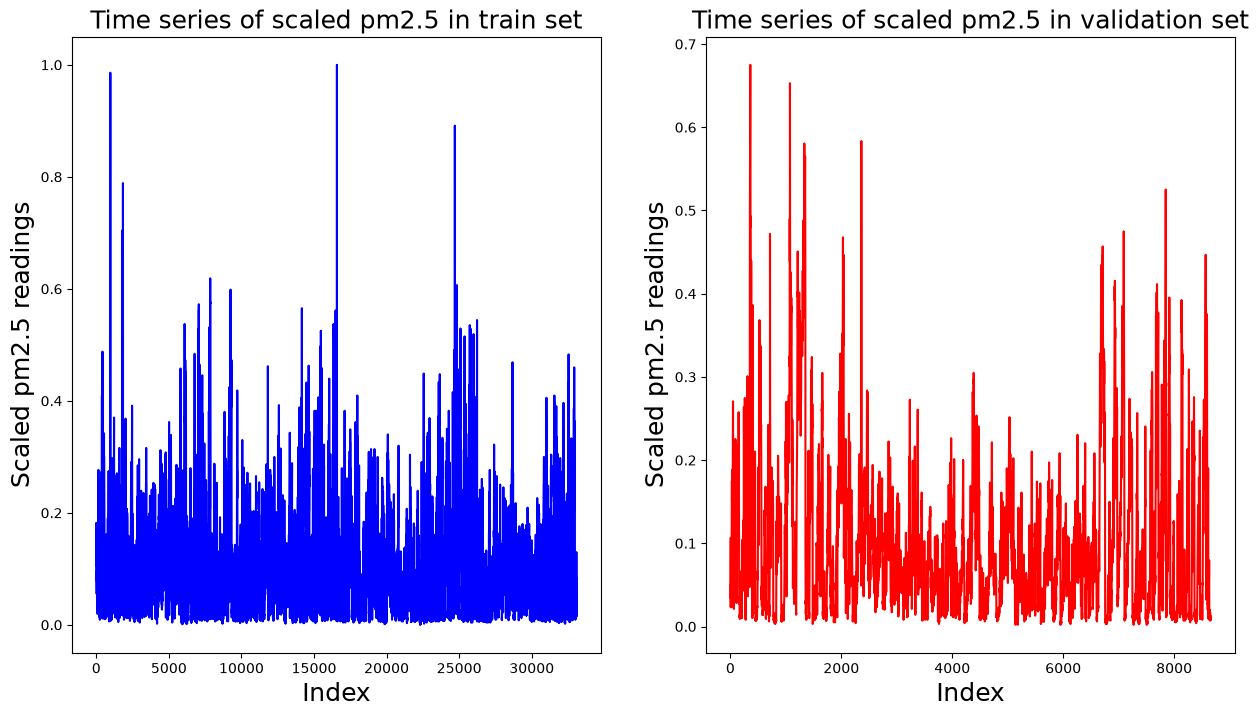

In [15]:
plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
g1 = sns.lineplot(df_train['scaled_pm2.5'], color='b')
g1.set_title('Time series of scaled pm2.5 in train set', fontsize=plot_fontsize)
g1.set_xlabel('Index', fontsize=plot_fontsize)
g1.set_ylabel('Scaled pm2.5 readings', fontsize=plot_fontsize);

plt.subplot(1, 2, 2)
g2 = sns.lineplot(df_val['scaled_pm2.5'], color='r')
g2.set_title('Time series of scaled pm2.5 in validation set', fontsize=plot_fontsize)
g2.set_xlabel('Index', fontsize=plot_fontsize)
g2.set_ylabel('Scaled pm2.5 readings', fontsize=plot_fontsize);

plt.show()

In [16]:
def makeXy(ts, nb_timesteps):
    """
    Input: 
           ts: original time series
           nb_timesteps: number of time steps in the regressors
    Output: 
           X: 2-D array of regressors
           y: 1-D array of target 
    """
    X = []
    y = []
    for i in range(nb_timesteps, ts.shape[0]):
        if i-nb_timesteps <= 4:
            print(i-nb_timesteps, i-1, i)
        X.append(list(ts.loc[i-nb_timesteps:i-1])) #Regressors
        y.append(ts.loc[i]) #Target
    X, y = np.array(X), np.array(y)
    return X, y

In [17]:
X_train, y_train = makeXy(df_train['scaled_pm2.5'], 7)

0 6 7
1 7 8
2 8 9
3 9 10
4 10 11


In [18]:
print('Shape of train arrays:', X_train.shape, y_train.shape)

Shape of train arrays: (33089, 7) (33089,)


In [19]:
X_val, y_val = makeXy(df_val['scaled_pm2.5'], 7)

0 6 7
1 7 8
2 8 9
3 9 10
4 10 11


In [20]:
print('Shape of validation arrays:', X_val.shape, y_val.shape)

Shape of validation arrays: (8654, 7) (8654,)


In [21]:
X_train, X_val = X_train.reshape((X_train.shape[0], X_train.shape[1], 1)), X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
print('Shape of 3D arrays:', X_train.shape, X_val.shape)

Shape of 3D arrays: (33089, 7, 1) (8654, 7, 1)


- `X_train` y `X_val` se han ***convertido en matrices 3D*** y sus nuevas formas se ven en la salida de la instrucción de impresión anterior

In [22]:
from keras.layers import Dense, Input, Dropout
from keras.layers import LSTM
from keras.optimizers import SGD
from keras.models import Model
from keras.models import load_model
from keras.callbacks import ModelCheckpoint

2026-11-06 14:34:18.360171: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-06 14:34:18.401702: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX_VNNI, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-06 14:34:19.339663: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


- La red neuronal para desarrollar el modelo de predicción de series temporales tiene una ***capa de entrada, que alimenta a la capa LSTM***. La capa LSTM tiene ***siete pasos temporales***, que es el mismo número de observaciones históricas tomadas para hacer la predicción de la presión atmosférica para el día siguiente. Solo ***el último paso temporal de la LSTM devuelve una salida***.

- Hay ***sesenta y cuatro neuronas ocultas en cada paso temporal de la capa LSTM***. Por lo tanto, la salida de la LSTM tiene sesenta y cuatro
características:

```{note}
La descripción original anterior menciona presión y 64 características. En el código de esta aplicación, la variable es **PM2.5** y se usan **dos LSTM**: la primera de 64 unidades y la segunda de 32. La ventana comprende siete observaciones y la salida pronostica la siguiente.
```


In [23]:
input_layer = Input(shape=(7,1), dtype='float32')

- Aquí `shape=(7,1)` forma de la ***entrada a la LSTM***. `7`: Número de ***pasos de tiempo (timesteps)***. `1`: Número de ***características (features) por cada paso de tiempo***. `return_sequences=True` se usa cuando se necesita ***pasar la secuencia completa de salidas a la siguiente capa de la red***, que también puede ser una capa recurrente como otra LSTM

In [24]:
lstm_layer1 = LSTM(64, input_shape=(7,1), return_sequences=True)(input_layer)
lstm_layer2 = LSTM(32, input_shape=(7,64), return_sequences=False)(lstm_layer1)

I0000 00:00:1793993661.194119    3692 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5262 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0


- A continuación, ***la salida de LSTM pasa a una capa de exclusión que elimina aleatoriamente el 20% de la entrada antes de pasar a la capa de salida***, que tiene una única neurona oculta con una función de ***activación lineal***

In [25]:
dropout_layer = Dropout(0.2)(lstm_layer2)

In [26]:
output_layer = Dense(1, activation='linear')(dropout_layer)

- Finalmente, todas las capas se envuelven en un `keras.models.Model` y se entrenan durante ***veinte epochs para minimizar el MSE*** utilizando el ***optimizador Adam***

```{note}
La descripción anterior menciona MSE y veinte épocas. Las celdas de código que siguen configuran **MAE** como pérdida y un máximo de **120 épocas**, con parada temprana. Se conservan ambos textos originales y se señala la diferencia.
```


In [27]:
ts_model = Model(inputs=input_layer, outputs=output_layer)
ts_model.compile(loss='mean_absolute_error', optimizer='adam') #SGD(lr=0.001, decay=1e-5))
ts_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 7, 1)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
import os
from joblib import dump, load
from keras.callbacks import EarlyStopping, ModelCheckpoint

In [29]:
save_weights_at = os.path.join('keras_models', 'PRSA_data_PM2.5_LSTM_weights.{epoch:02d}-{val_loss:.4f}.keras')

checkpointer = [
    EarlyStopping(
        monitor='val_loss',  
        verbose=1,
        restore_best_weights=True,
        mode='min',
        patience=10
    ),
    ModelCheckpoint(
        filepath=save_weights_at,
        monitor='val_loss',
        verbose=1,
        save_best_only=True,
        save_weights_only=False,
        mode='min',
        save_freq='epoch'
    )
]

In [30]:
history_pm25_LSTM = None

if os.path.exists('history_pm25_LSTM.joblib'):
    history_pm25_LSTM = load('history_pm25_LSTM.joblib')
    print("El archivo 'history_pm25_LSTM.joblib' ya existe. Se ha cargado el historial del entrenamiento.")
else:
    history_pm25_LSTM = ts_model.fit(
        x=X_train, 
        y=y_train, 
        batch_size=16, 
        epochs=120,
        verbose=2, 
        callbacks=checkpointer,
        validation_data=(X_val, y_val),
        shuffle=True
    )
    dump(history_pm25_LSTM.history, 'history_pm25_LSTM.joblib')
    print("El entrenamiento se ha completado y el historial ha sido guardado en 'history_pm25_LSTM.joblib'.")

Epoch 1/120


I0000 00:00:1793993664.876623    4222 cuda_dnn.cc:530] Loaded cuDNN version 92301



Epoch 1: val_loss improved from None to 0.01231, saving model to keras_models/PRSA_data_PM2.5_LSTM_weights.01-0.0123.keras

Epoch 1: finished saving model to keras_models/PRSA_data_PM2.5_LSTM_weights.01-0.0123.keras
2069/2069 - 21s - 10ms/step - loss: 0.0194 - val_loss: 0.0123
Epoch 2/120

Epoch 2: val_loss did not improve from 0.01231
2069/2069 - 20s - 10ms/step - loss: 0.0152 - val_loss: 0.0132
Epoch 3/120

Epoch 3: val_loss improved from 0.01231 to 0.01202, saving model to keras_models/PRSA_data_PM2.5_LSTM_weights.03-0.0120.keras

Epoch 3: finished saving model to keras_models/PRSA_data_PM2.5_LSTM_weights.03-0.0120.keras
2069/2069 - 18s - 9ms/step - loss: 0.0152 - val_loss: 0.0120
Epoch 4/120

Epoch 4: val_loss did not improve from 0.01202
2069/2069 - 19s - 9ms/step - loss: 0.0149 - val_loss: 0.0143
Epoch 5/120

Epoch 5: val_loss did not improve from 0.01202
2069/2069 - 19s - 9ms/step - loss: 0.0149 - val_loss: 0.0128
Epoch 6/120

Epoch 6: val_loss improved from 0.01202 to 0.01160,

In [31]:
import re

In [32]:
model_dir = 'keras_models'
files = os.listdir(model_dir)
pattern = r"PRSA_data_PM2.5_LSTM_weights\.(\d+)-([\d\.]+)\.keras"
    
best_val_loss = float('inf')
best_model_file = None
best_model = None

for file in files:
    match = re.match(pattern, file)
    if match:
        epoch = int(match.group(1))
        val_loss = float(match.group(2))
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_file = file

if best_model_file:
    best_model_path = os.path.join(model_dir, best_model_file)
    print(f"Cargando el mejor modelo: {best_model_file} con val_loss: {best_val_loss}")
    best_model = load_model(best_model_path)
else:
    print("No se encontraron archivos de modelos que coincidan con el patrón.")

Cargando el mejor modelo: PRSA_data_PM2.5_LSTM_weights.06-0.0116.keras con val_loss: 0.0116


In [33]:
preds = best_model.predict(X_val)
pred_pm25 = scaler_pm25.inverse_transform(preds)
pred_pm25 = np.squeeze(pred_pm25)

271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [34]:
from sklearn.metrics import mean_absolute_error

In [35]:
mae = mean_absolute_error(df_val['pm2.5'].loc[7:], pred_pm25)
print('MAE for the validation set:', round(mae, 4))

MAE for the validation set: 11.5308


- Hemos utilizado `keras.callbacks.ModelCheckpoint` como callback para rastrear el `MSE` del modelo en el conjunto de validación y ***guardar los pesos de la epoch que da el mínimo MSE***. El `R-cuadrado` del mejor modelo para el conjunto de validación es de 0.9959. Los primeros cincuenta valores reales y predichos se muestran en la siguiente figura

```{note}
La celda de evaluación original calcula **MAE**, no $R^2$. La cifra de $R^2$ mencionada en el texto anterior no queda verificada por las celdas de esta aplicación.
```


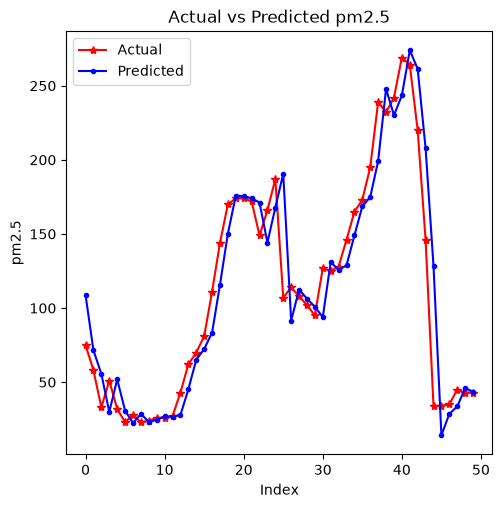

In [36]:
plt.figure(figsize=(5.5, 5.5))
plt.plot(range(50), df_val['pm2.5'].loc[7:56], linestyle='-', marker='*', color='r')
plt.plot(range(50), pred_pm25[:50], linestyle='-', marker='.', color='b')
plt.legend(['Actual','Predicted'], loc=2)
plt.title('Actual vs Predicted pm2.5')
plt.ylabel('pm2.5')
plt.xlabel('Index');

## Proyecto integrador de series de tiempo

Se mantienen los **objetivos, datos y tareas** del proyecto del archivo original, orientando la actividad de modelado a una **RNN o LSTM**. Se omiten únicamente los ejemplos específicos del modelo retirado. Los fragmentos de código que se conservan permanecen **sin cambios**.


## Proyecto Integrador de Deep Learning
**Objetivo**

- El proyecto busca **predecir una variable temporal de interés**, como el **precio de cierre de criptomonedas** o la **velocidad del viento**, utilizando exclusivamente su **histórico temporal** (por ejemplo, fecha y valores observados). Para ello, se emplea la librería [timeseries-cv](https://pypi.org/project/timeseries-cv/), junto con **estrategias de validación temporal**, un modelo recurrente RNN o LSTM y un análisis riguroso de residuos.

- Adicionalmente, se propone **construir, validar y desplegar un modelo robusto de deep learning**, orientado tanto a la **predicción del nivel de la serie** como a la **modelación de su volatilidad o variabilidad**, partiendo únicamente de observaciones históricas.

- El flujo de trabajo incluye:

    - Exploración y caracterización de la variabilidad de la serie  
    - Construcción de ventanas temporales  
    - Validación cruzada para datos secuenciales  
    - Evaluación mediante métricas específicas  
    - Análisis de residuos  

- Todo ello con el objetivo final de su **despliegue en un entorno de MLOps**.
**Contexto**

- Las series temporales asociadas a **criptomonedas** y a **variables ambientales como la velocidad del viento** comparten características fundamentales como:

    - Alta variabilidad  
    - No linealidad  
    - Dependencia temporal compleja  
    - Posibles cambios de régimen  

- Estas propiedades representan tanto un desafío como una oportunidad para el desarrollo de modelos predictivos avanzados. En el caso de las criptomonedas, la alta volatilidad impacta directamente en:

    - Trading algorítmico  
    - Gestión de portafolios  
    - Estimación de riesgos  

- Por su parte, en el ámbito energético y ambiental, la predicción de la velocidad del viento es clave para:

    - Planificación de sistemas de generación eólica  
    - Optimización operativa  
    - Gestión de incertidumbre en energías renovables  

- En ambos contextos, si bien la predicción puntual de la serie es relevante, **modelar y anticipar la variabilidad o volatilidad proporciona una base más robusta para la toma de decisiones bajo incertidumbre**.

- Por ello, el *forecasting* de series temporales, cuando se aborda de manera **rigurosa, reproducible y orientada a datos reales**, se consolida como una tarea central en la ciencia de datos aplicada tanto a sistemas financieros como a sistemas energéticos y ambientales.

- **Datasets recomendados:**  
  - Fuente: [Binance Public API](https://www.binance.com/en/binance-api). API gratuita, sin registro, y es la fuente más citada en literatura académica de alta frecuencia. **Seleccione la criptomoneda de su interés para esta tarea o el dataset de velocidad del viento**. Ejemplo de uso de la API de Binance
 
````python
import requests, pandas as pd, time
from datetime import datetime

def get_binance_1m(symbol="BTCUSDT", start="2024-01-01", end="2024-01-31"):
    url = "https://api.binance.com/api/v3/klines"
    start_ms = int(datetime.strptime(start, "%Y-%m-%d").timestamp() * 1000)
    end_ms   = int(datetime.strptime(end,   "%Y-%m-%d").timestamp() * 1000)
    all_data = []

    while start_ms < end_ms:
        params = {
            "symbol": symbol,
            "interval": "1m",
            "startTime": start_ms,
            "endTime": end_ms,
            "limit": 1000
        }
        r = requests.get(url, params=params)
        data = r.json()
        if not data: break
        all_data.extend(data)
        start_ms = data[-1][0] + 60000  # avanza 1 minuto
        time.sleep(0.1)  # evita rate limit

    df = pd.DataFrame(all_data, columns=[
        "open_time","open","high","low","close","volume",
        "close_time","quote_volume","trades",
        "taker_buy_base","taker_buy_quote","ignore"
    ])
    df["open_time"] = pd.to_datetime(df["open_time"], unit="ms")
    df[["open","high","low","close","volume"]] = \
        df[["open","high","low","close","volume"]].astype(float)
    return df[["open_time","open","high","low","close","volume","trades"]]

df = get_binance_1m("BTCUSDT", "2024-01-01", "2024-03-31")
df.to_csv("btc_1m_Q1_2024.csv", index=False)
print(df.shape)
````


- Frecuencia: 1 minuto.  
- Variable clave: Precio de Cierre (`Close`)
- **Cálculo de la volatilidad: definición formal y ejemplo:**  
  - La volatilidad es una medida de **dispersión de los rendimientos de un activo financiero**.
  - Para una ventana de tamaño $n$:

    $$
    \sigma_t = \sqrt{ \frac{1}{n} \sum_{i=1}^{n} (r_{t-i} - \bar{r})^2},~\text{donde}~r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
    $$

    - $P_t$: Precio de cierre en el día $t$
    - $r_t$: Retorno logarítmico diario
    - $\sigma_t$: Volatilidad histórica realizada en ventana de $n$ días
    - $\bar{r}$: Promedio de los retornos en la ventana

- Datos del [INMET - National Institute of Meteorology](https://portal.inmet.gov.br/dadoshistoricos) relacionados con velocidad del viento. La variable respuesta en este caso es la velocidad de viento suministrada de forma horaria por INMET. **Debe seleccionar solo un dataset, el de velocidad del viento o el de criptomonedas**.

- **Actividades a desarrollar**. Cada resultado debe ir acompañado de **análisis, justificación y visualización/tablas** cuando sea relevante.  

    - **Análisis Exploratorio de Datos (EDA)**
      
    - Estadísticas descriptivas de precios y retornos.  
    - Visualizaciones: serie de precios, retornos diarios, histograma de retornos, autocorrelación (ACF) y ACF de cuadrados (para heterocedasticidad).
      
    - **Preprocesamiento y cálculo de features**
    
    - Cálculo de **retornos logarítmicos**.  
    - Cálculo de **volatilidad histórica (rolling std)** para inspección (variable objetivo alternativa).  
    - Generación de **lags del precio** (ventanas previas) para los siguientes tamaños: 7, 14, 21, 28 días.  
    - Generación de **targets multi-step**: horizonte de 7 días (salida multisalida de longitud 7).  
    
    - **Split temporal y validación cruzada**
    
    - Usar `split_train_val_test_groupKFold` (de [**timeseries-cv / tsxv**](https://pypi.org/project/timeseries-cv/)) para crear splits **train / val / test** sin data leakage.  
    - Escalado: **fit del scaler solo con el train** en cada fold; transformar val/test con ese scaler.  
    
    - **Modelado con Deep Learning**
    
    - Entrenar una **RNN o LSTM multisalida** con horizonte 7, fold a fold.  
    - Guardar por fold: **predicciones para train, val y test** (todas las muestras del fold).  
    - Evaluación: calcular **métricas por horizonte (1..7) y agregadas (promedio sobre horizontes)**.  
    
    - **Métricas obligatorias — tablas por tamaño de input**
    
    Por cada tamaño de input (7, 14, 21, 28) se debe entregar una **tabla (en el conjunto de test)** que incluya, idealmente por fold y con su promedio (y std):  
    
    - **MAPE** (Mean Absolute Percentage Error) — por horizonte y promedio.  
    - **MAE** (Mean Absolute Error).  
    - **RMSE** (Root Mean Squared Error).  
    - **MSE** (Mean Squared Error).  
    - **$p$-value BDS test** aplicado a los residuos del primer horizonte ($h=1$) (por fold) — y su promedio.  
    
    **Formato recomendado de la tabla (por lag):**  
    
    - Filas = folds (Fold 1, Fold 2, ... , Mean ± Std).  
    - Columnas = métricas por horizonte ($h=1,\dots,7$) o resumen por horizonte + columna con **BDS_pvalue_h1**.  
    
    - **Diagnóstico de residuos**
    
    - En cada fold, calcular residuos en test $\text{resid} = y_{test}^{\text{real}} - y_{pred}$
        
    - Aplicar **BDS test** a los residuos del horizonte 1 (test de independencia serial / no-iid).  
    - Reportar el **$p$-value**.  
    - Interpretación: **$p > 0.05$ → no rechazo de iid (mejor señal de independencia residual)**.  
    
    - **Visualización y análisis**
    
    Para cada tamaño de input:  
    
    - Dibujar una **curva (time series)** que muestre **train / val / test** (validados con sus timestamps) y las **predicciones correspondientes** (por lo menos para el mejor fold, el peor fold y el fold mediano por RMSE).  
    - Etiquetar claramente: **train actual, train predicho, val actual, val predicho, test actual, test predicho**.  
    - Gráfica de **RMSE por fold** (e.g., barras) y **RMSE promedio por horizonte** (líneas con 7 puntos).  
    - **Tabla resumen comparativa** de los 4 tamaños de lag con las métricas solicitadas (MAPE, MAE, RMSE, MSE, p-value BDS).  
    - Guardar figuras en `notebooks/figs/` y las tablas en `results/` (CSV).  
    
    - **Documentación y deployment**
    
        - Entregar **notebook reproducible** con todo el pipeline (**EDA → features → CV → entrenamiento → evaluación → residuos → plots**).  
        - Entregar **API (`app/api.py`)** que reciba lags y devuelva **7 predicciones de volatilidad** (lista de floats).  
        - Incluir **Dockerfile, tests unitarios y README** con instrucciones de uso.


```{note}
La ausencia de rechazo en la prueba BDS no demuestra que los residuos sean independientes. Los fragmentos de despliegue siguientes se conservan como plantillas originales; su compatibilidad con una implementación recurrente debe verificarse en el entorno elegido.
```


6. **Instrucciones para el entorno de MLOps**

- Para construir el entorno de MLOps correspondiente al problema planteado (**predicción multistep del nivel y/o volatilidad de una serie temporal**, como el precio de criptomonedas o la velocidad del viento), es necesario instalar las bibliotecas asociadas al modelado temporal, deep learning, validación cruzada temporal y análisis de residuos.

```bash
python -m pip install --force-reinstall pydantic
python -m pip install fastapi[all]
python -m pip install joblib
python -m pip install pandas
python -m pip install scikit-learn
python -m pip install matplotlib
python -m pip install tsxv
python -m pip install arch
````
7. Estructura general del proyecto

La estructura del proyecto debe incluir datos, notebooks, aplicación, pruebas y configuración de despliegue.


8. API con FastAPI (`api.py`)

```python
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import numpy as np

app = FastAPI()
model = joblib.load("app/model.joblib")

class TimeSeriesData(BaseModel):
    lags: list[float]   # Ventanas históricas (ej. últimos valores observados)

@app.post("/predict")
def predict(data: TimeSeriesData):
    features = np.array(data.lags).reshape(1, -1)
    prediction = model.predict(features)[0]
    return {"prediction": prediction.tolist()}
```
9. Dockerfile

```dockerfile
FROM python:3.10-slim

WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY app/ ./app/
COPY data/ ./data/

EXPOSE 8000
CMD ["uvicorn", "app.api:app", "--host", "0.0.0.0", "--port", "8000"]
```
10. requirements.txt

```text
fastapi>=0.95.0
uvicorn
scikit-learn
pandas
numpy
joblib
matplotlib
tsxv
arch
```
11. CI/CD con GitHub Actions

```yaml
name: CI Pipeline
on: [push, pull_request]

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v3
      - name: Set up Python
        uses: actions/setup-python@v4
        with:
          python-version: 3.10
      - name: Install dependencies
        run: |
          pip install -r requirements.txt
          pip install pytest flake8
      - name: Run Linter
        run: flake8 app/ --ignore=E501,W503
      - name: Run Tests
        run: pytest tests/
```

12. Pruebas unitarias del modelo

```python
import joblib
import numpy as np

def test_model_prediction_shape():
    model = joblib.load("app/model.joblib")
    X_test = np.random.rand(5, 7)
    y_pred = model.predict(X_test)
    assert y_pred.shape == (5, 7)

def test_prediction_values():
    model = joblib.load("app/model.joblib")
    X = np.random.rand(1, 7)
    y_pred = model.predict(X)[0]
    assert len(y_pred) == 7
    assert all(isinstance(v, (float, np.floating)) for v in y_pred)
```

13. Pruebas unitarias de la API

```python
from fastapi.testclient import TestClient
from app.api import app

client = TestClient(app)

def test_predict_endpoint():
    response = client.post("/predict", json={"lags": [1.0, 1.2, 1.1, 1.3, 1.25, 1.28, 1.35]})
    assert response.status_code == 200
    data = response.json()
    assert "prediction" in data
    assert isinstance(data["prediction"], list)
    assert len(data["prediction"]) == 7
```

14. Prueba local con curl

```bash
curl -X POST http://localhost:8000/predict \
   -H "Content-Type: application/json" \
   -d '{"lags": [1.0, 1.2, 1.1, 1.3, 1.25, 1.28, 1.35]}'
```

Salida esperada:

```json
{
  "prediction": [
    0.12,
    0.11,
    0.10,
    0.09,
    0.08,
    0.07,
    0.06
  ]
}
```


## Referencias de la aplicación

- Chen, S. (2015). *Beijing PM2.5* [conjunto de datos]. UCI Machine Learning Repository. [https://doi.org/10.24432/C5JS49](https://doi.org/10.24432/C5JS49).
- **Copia utilizada en el código original:** [archivo CSV en GitHub](https://github.com/lihkir/Data/blob/main/PRSA_data_2010.1.1-2014.12.31.csv).
- **Documentación de Keras:** [capas LSTM](https://keras.io/api/layers/recurrent_layers/lstm/) y [callbacks](https://keras.io/api/callbacks/).
- **Proyecto integrador:** se conservan en el enunciado los enlaces originales de Binance, INMET y `timeseries-cv`.
